# Forward kinematics demo

In [1]:
import sys
if '../' not in sys.path:
    sys.path.append('../')

In [2]:
import numpy as np

from hmp_utils import BodyModelType, SmplConstants, H36MConstants, ForwardKinematics
from hmp_utils.motion.mocap_processor import MocapLoader
from hmp_utils.visualize.static_3d_plot import plot_body_keypoints
from hmp_utils.visualize.stickman_animation import pose_animation, CameraOrientation, AnimationMode

## Compute forward kinematics for SMPL

- local positions
- global positions

In [3]:
filepath = './example_mocaps/walking_poses.npz'
animation_framerate = 30

# -- load mocap --
mocap_loader=MocapLoader(body_model_type=SmplConstants.BODY_MODEL_TYPE,
                         keypoint_ids_to_load=SmplConstants.KEYPOINTS,
                         target_framerate=animation_framerate)
motion = mocap_loader.load_mocap(filepath)
assert motion is not None

# -- compute joint positions --
kine = ForwardKinematics(SmplConstants.OFFSETS, SmplConstants.PARENTS)
kine.set_body_model_type(BodyModelType.SMPL)

# local keypoint positions (relative to the root joint)
keypoints_positions = kine.compute_fk(motion.rots, apply_root_rotation=True)

# global keypoint positions (sum the given root_translations)
keypoints_positions_glob = kine.compute_fk(motion.rots, apply_root_rotation=True, 
                                           root_translation=motion.trans)

### Add global translations

After computing the local forward kinematics, one can choose to sum the translations, making the joint positions global instead of local (instead of passing the translations to the `compute_fk()` function)

```
keypoints_positions_glob = keypoints_positions + motion.trans
```

#### Animation

In [4]:
subplot_ids = [0, 1]
subplot_titles = ['local position', 'global positions']
camera_orientations = [CameraOrientation(100, 20), CameraOrientation(100, 20)]
pose_animation([keypoints_positions, keypoints_positions_glob], 
               SmplConstants.PARENTS, animation_framerate, subplot_ids=subplot_ids, 
               camera_orientations=camera_orientations, subplot_titles=subplot_titles,
               animation_mode=AnimationMode.HTML5)

### Normalize body pose

Following SPL ([code](https://github.com/eth-ait/spl)), the joint lengths can be normalized so that the positional metric is not biased towards bodies of smaller sizes.

Here the normalization is done to the right thigh (index 5 because that's the right knee keypoint)

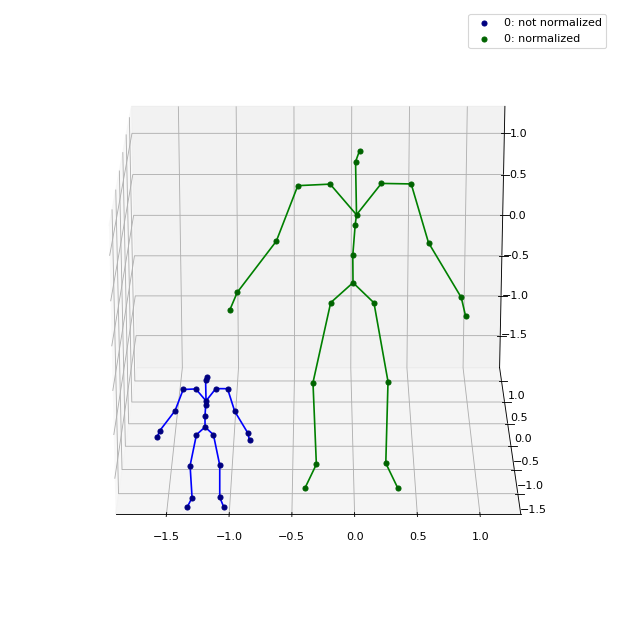

In [5]:
# local keypoint positions (relative to the root joint)
assert motion is not None

frame_to_plot = 10

kine.normalize_joints(reference_joint=5)
keypoints_positions_normalized = kine.compute_fk(motion.rots, apply_root_rotation=True)

plot_body_keypoints([keypoints_positions[frame_to_plot]-1.2, keypoints_positions_normalized[frame_to_plot]], 
                    [SmplConstants.PARENTS, SmplConstants.PARENTS], num_independent_bodies=2, show_grid=True,
                    image_margins_factor=0.8, keypoint_names=[['not normalized'], ['normalized']],
                    show_keypoint_id=False, azimuth=-90)

## Forward kinematics for Human 3.6 M

The kinematics is a bit different, due to:
- the offsets of Human3.6M being relative (as opposed to AMASS where they come as absolute)
- the kinematics is calculated by applying a "left" matrix multiplication between the offset and rotation (for the keypoint position) and for the keypoint orientation

This means that the forward kinematics object will need 2 parameters to be true (while they are false on SMPL-like body poses).

Also, we divide the position by 1000 since the unit of measure was millimeters, but we convert to meters in order to conform to SMPL and AMASS.

In [6]:
filepath = './example_mocaps/human_ang_sample.npy' # [25,33,3]
motion = np.load(filepath)  # [frame,joint,3] angle-axis notation
assert motion is not None

frame_to_plot = 10

# -- remove global position -- 
motion = np.array(motion[:,1:,:])

# -- compute joint positions --
kine = ForwardKinematics(H36MConstants.OFFSETS, H36MConstants.PARENTS)
kine.set_body_model_type(BodyModelType.H36M)
keypoints_positions = kine.compute_fk(motion)/1000

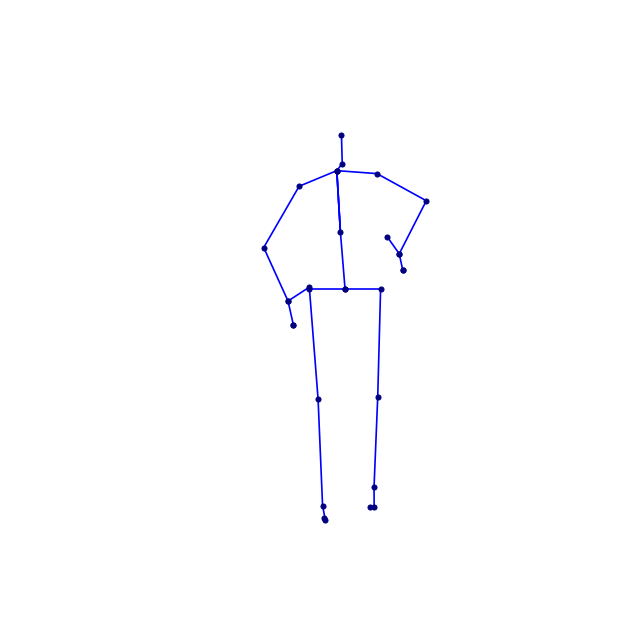

In [7]:
plot_body_keypoints(keypoints_positions[frame_to_plot], H36MConstants.PARENTS, show_keypoint_id=False, azimuth=-90, elevation=120)